In [1]:
# Experiment with Regularization Techniques
# o Train a model with and without L2 regularization.
# o Add Dropout and compare performance.
# o Visualize training/validation loss and accuracy.

In [1]:
# Import libraries
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

I0000 00:00:1794473568.990292    5267 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794473569.102664    5267 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794473571.956418    5267 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# Load and preprocess data
train = pd.read_csv("dataset/Fashion/fashion-mnist_train.csv")
test = pd.read_csv("dataset/Fashion/fashion-mnist_test.csv")

x_train = train.iloc[:, 1:].values.astype('float32') / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values.astype('float32') / 255.0
y_test = test.iloc[:, 0].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)
print("Missing values:", train.isnull().sum().sum())

Training data: (60000, 784)
Testing data: (10000, 784)
Missing values: 0


In [3]:
# Build and train 3 models
histories = []
results = []

for name in ['Normal', 'L2', 'Dropout']:
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001) if name == 'L2' else None)
    ])

    if name == 'Dropout':
        model.add(tf.keras.layers.Dropout(0.5))

    model.add(tf.keras.layers.Dense(10, activation='softmax'))

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=1)

    loss, acc = model.evaluate(x_test, y_test, verbose=0)

    histories.append(history)
    results.append(acc)

    print(name, "Test Accuracy:", acc * 100, "%")

E0000 00:00:1794473607.581988    5267 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/5


W0000 00:00:1794473608.126042    5267 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8128 - loss: 0.5387 - val_accuracy: 0.8515 - val_loss: 0.4381
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.8579 - loss: 0.4024 - val_accuracy: 0.8625 - val_loss: 0.3914
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.8698 - loss: 0.3615 - val_accuracy: 0.8732 - val_loss: 0.3654
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.8762 - loss: 0.3382 - val_accuracy: 0.8712 - val_loss: 0.3669
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.8850 - loss: 0.3156 - val_accuracy: 0.8763 - val_loss: 0.3512


W0000 00:00:1794473673.635566    5267 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


Normal Test Accuracy: 87.87999749183655 %
Epoch 1/5


... (2 outputs left out)

W0000 00:00:1794473744.387160    5267 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


L2 Test Accuracy: 86.66999936103821 %
Epoch 1/5


W0000 00:00:1794473746.543458    5267 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.7671 - loss: 0.6623 - val_accuracy: 0.8260 - val_loss: 0.4782
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8279 - loss: 0.4835 - val_accuracy: 0.8542 - val_loss: 0.4206
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8401 - loss: 0.4467 - val_accuracy: 0.8642 - val_loss: 0.3982
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.8461 - loss: 0.4267 - val_accuracy: 0.8658 - val_loss: 0.3846
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.8523 - loss: 0.4110 - val_accuracy: 0.8593 - val_loss: 0.3761
Dropout Test Accuracy: 86.87999844551086 %


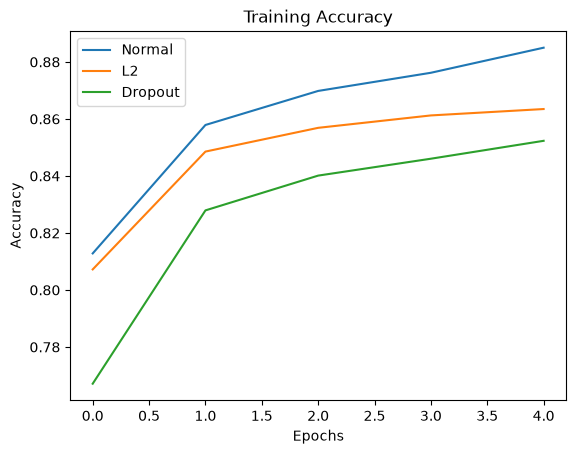

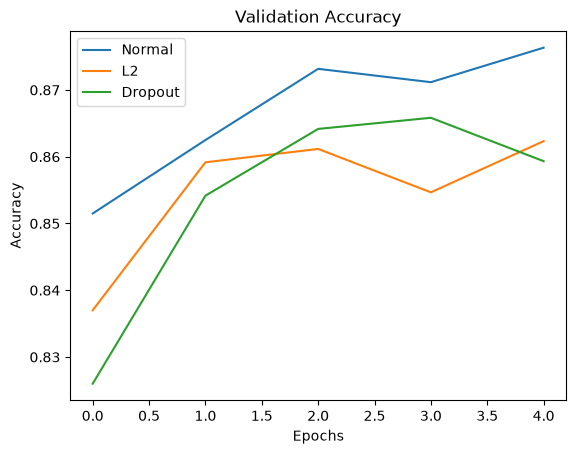

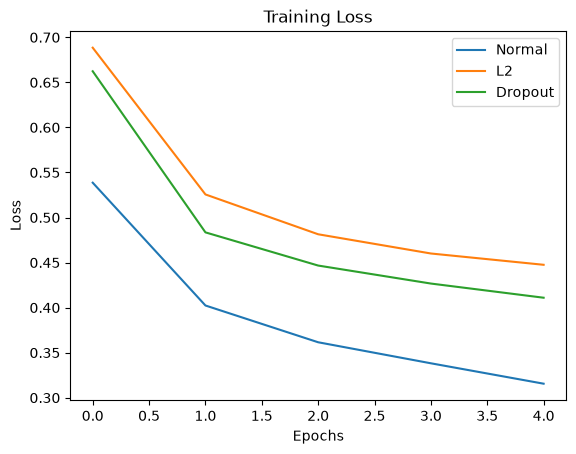

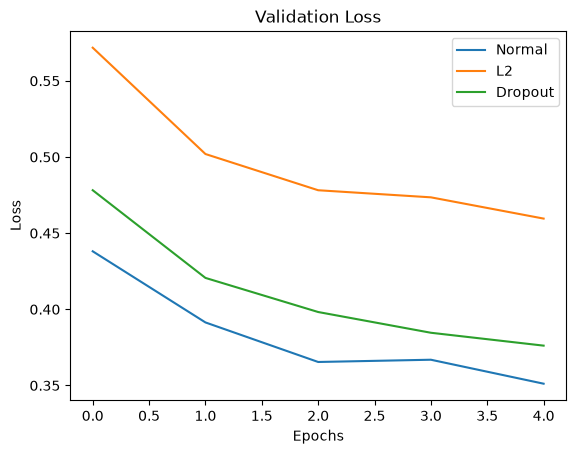

In [5]:
# Compare training and validation accuracy
for i, h in enumerate(histories):
    plt.plot(h.history['accuracy'], label=['Normal', 'L2', 'Dropout'][i])

plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

for i, h in enumerate(histories):
    plt.plot(h.history['val_accuracy'], label=['Normal', 'L2', 'Dropout'][i])

plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Compare training and validation loss
for i, h in enumerate(histories):
    plt.plot(h.history['loss'], label=['Normal', 'L2', 'Dropout'][i])

plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

for i, h in enumerate(histories):
    plt.plot(h.history['val_loss'], label=['Normal', 'L2', 'Dropout'][i])

plt.title("Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()